In [2]:

import pandas as pd

data = pd.read_csv("creditcard.csv")

print(data.head())
print(data.shape)
print(data["Class"].value_counts())


   Time        V1        V2        V3        V4        V5        V6        V7  \
0   0.0 -1.359807 -0.072781  2.536347  1.378155 -0.338321  0.462388  0.239599   
1   0.0  1.191857  0.266151  0.166480  0.448154  0.060018 -0.082361 -0.078803   
2   1.0 -1.358354 -1.340163  1.773209  0.379780 -0.503198  1.800499  0.791461   
3   1.0 -0.966272 -0.185226  1.792993 -0.863291 -0.010309  1.247203  0.237609   
4   2.0 -1.158233  0.877737  1.548718  0.403034 -0.407193  0.095921  0.592941   

         V8        V9  ...       V21       V22       V23       V24       V25  \
0  0.098698  0.363787  ... -0.018307  0.277838 -0.110474  0.066928  0.128539   
1  0.085102 -0.255425  ... -0.225775 -0.638672  0.101288 -0.339846  0.167170   
2  0.247676 -1.514654  ...  0.247998  0.771679  0.909412 -0.689281 -0.327642   
3  0.377436 -1.387024  ... -0.108300  0.005274 -0.190321 -1.175575  0.647376   
4 -0.270533  0.817739  ... -0.009431  0.798278 -0.137458  0.141267 -0.206010   

        V26       V27       V28 

In [3]:

from sklearn.model_selection import train_test_split

X = data.drop("Class", axis=1)
y = data["Class"]

X_train, X_test, y_train, y_test = train_test_split(
    X, y,
    test_size=0.2,
    random_state=42,
    stratify=y
)

print("Training data:", X_train.shape)
print("Testing data:", X_test.shape)
print("Training fraud cases:", y_train.sum())
print("Testing fraud cases:", y_test.sum())


Training data: (227845, 30)
Testing data: (56962, 30)
Training fraud cases: 394
Testing fraud cases: 98


In [4]:

from sklearn.ensemble import RandomForestClassifier

model = RandomForestClassifier(
    n_estimators=100,
    random_state=42,
    class_weight="balanced",
    n_jobs=-1
)

model.fit(X_train, y_train)

print("Model training complete!")


Model training complete!


In [5]:

from sklearn.metrics import accuracy_score, precision_score, recall_score, f1_score, confusion_matrix

predictions = model.predict(X_test)

print("Accuracy:", accuracy_score(y_test, predictions))
print("Precision:", precision_score(y_test, predictions, zero_division=0))
print("Recall:", recall_score(y_test, predictions, zero_division=0))
print("F1 Score:", f1_score(y_test, predictions, zero_division=0))

print("\nConfusion Matrix:")
print(confusion_matrix(y_test, predictions))


Accuracy: 0.9995084442259752
Precision: 0.9605263157894737
Recall: 0.7448979591836735
F1 Score: 0.8390804597701149

Confusion Matrix:
[[56861     3]
 [   25    73]]


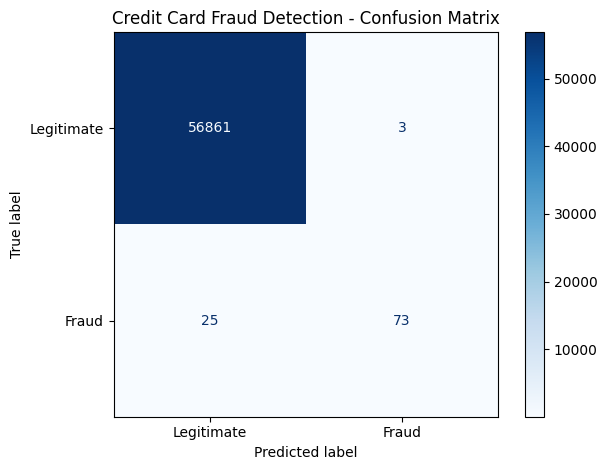

In [6]:

import matplotlib.pyplot as plt
from sklearn.metrics import ConfusionMatrixDisplay

ConfusionMatrixDisplay.from_predictions(
    y_test,
    predictions,
    display_labels=["Legitimate", "Fraud"],
    cmap="Blues",
    values_format="d"
)

plt.title("Credit Card Fraud Detection - Confusion Matrix")
plt.tight_layout()
plt.savefig("confusion_matrix.png", dpi=300)
plt.show()


In [7]:

from sklearn.dummy import DummyClassifier
from sklearn.metrics import classification_report

baseline = DummyClassifier(strategy="most_frequent")
baseline.fit(X_train, y_train)

baseline_predictions = baseline.predict(X_test)

print("Baseline Model:")
print(classification_report(
    y_test,
    baseline_predictions,
    zero_division=0
))

print("\nRandom Forest Model:")
print(classification_report(
    y_test,
    predictions,
    zero_division=0
))


Baseline Model:
              precision    recall  f1-score   support

           0       1.00      1.00      1.00     56864
           1       0.00      0.00      0.00        98

    accuracy                           1.00     56962
   macro avg       0.50      0.50      0.50     56962
weighted avg       1.00      1.00      1.00     56962


Random Forest Model:
              precision    recall  f1-score   support

           0       1.00      1.00      1.00     56864
           1       0.96      0.74      0.84        98

    accuracy                           1.00     56962
   macro avg       0.98      0.87      0.92     56962
weighted avg       1.00      1.00      1.00     56962



In [8]:

from sklearn.metrics import precision_score, recall_score, f1_score

probabilities = model.predict_proba(X_test)[:, 1]

for threshold in [0.5, 0.4, 0.3, 0.2, 0.1]:
    new_predictions = (probabilities >= threshold).astype(int)

    precision = precision_score(y_test, new_predictions, zero_division=0)
    recall = recall_score(y_test, new_predictions, zero_division=0)
    f1 = f1_score(y_test, new_predictions, zero_division=0)

    print("Threshold:", threshold)
    print("Precision:", round(precision, 4))
    print("Recall:", round(recall, 4))
    print("F1 Score:", round(f1, 4))
    print()


Threshold: 0.5
Precision: 0.9605
Recall: 0.7449
F1 Score: 0.8391

Threshold: 0.4
Precision: 0.9518
Recall: 0.8061
F1 Score: 0.8729

Threshold: 0.3
Precision: 0.9222
Recall: 0.8469
F1 Score: 0.883

Threshold: 0.2
Precision: 0.8571
Recall: 0.8571
F1 Score: 0.8571

Threshold: 0.1
Precision: 0.7414
Recall: 0.8776
F1 Score: 0.8037



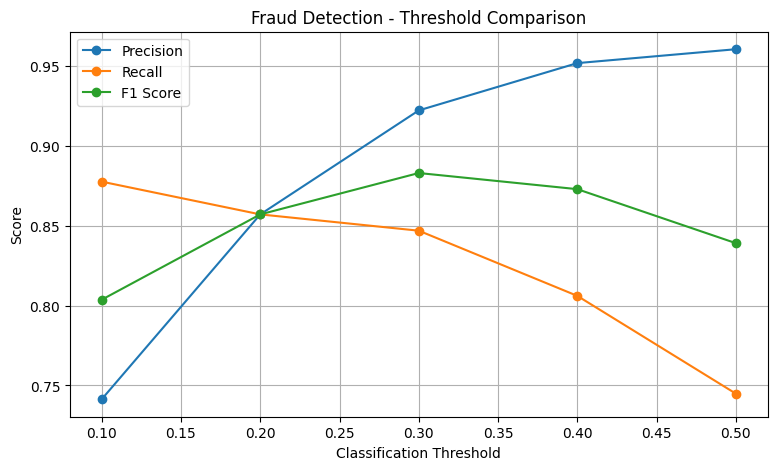

In [9]:

import matplotlib.pyplot as plt

thresholds = [0.5, 0.4, 0.3, 0.2, 0.1]
precision = [0.9605, 0.9518, 0.9222, 0.8571, 0.7414]
recall = [0.7449, 0.8061, 0.8469, 0.8571, 0.8776]
f1 = [0.8391, 0.8729, 0.8830, 0.8571, 0.8037]

plt.figure(figsize=(9, 5))

plt.plot(thresholds, precision, marker="o", label="Precision")
plt.plot(thresholds, recall, marker="o", label="Recall")
plt.plot(thresholds, f1, marker="o", label="F1 Score")

plt.xlabel("Classification Threshold")
plt.ylabel("Score")
plt.title("Fraud Detection - Threshold Comparison")
plt.legend()
plt.grid(True)

plt.savefig("threshold_comparison.png", dpi=300, bbox_inches="tight")
plt.show()


In [10]:

from sklearn.model_selection import train_test_split
from sklearn.ensemble import RandomForestClassifier
from sklearn.metrics import f1_score, classification_report, confusion_matrix

X = data.drop("Class", axis=1)
y = data["Class"]

X_train_new, X_temp, y_train_new, y_temp = train_test_split(
    X, y, test_size=0.4, random_state=42, stratify=y
)

X_val, X_test_new, y_val, y_test_new = train_test_split(
    X_temp, y_temp, test_size=0.5, random_state=42, stratify=y_temp
)

new_model = RandomForestClassifier(
    n_estimators=100,
    random_state=42,
    class_weight="balanced",
    n_jobs=-1
)

new_model.fit(X_train_new, y_train_new)

val_probabilities = new_model.predict_proba(X_val)[:, 1]

best_threshold = 0.5
best_f1 = 0

for threshold in [0.1, 0.2, 0.3, 0.4, 0.5]:
    val_predictions = (val_probabilities >= threshold).astype(int)
    score = f1_score(y_val, val_predictions)

    print("Threshold:", threshold, "Validation F1:", round(score, 4))

    if score > best_f1:
        best_f1 = score
        best_threshold = threshold

print("\nBest validation threshold:", best_threshold)
print("Best validation F1:", round(best_f1, 4))


Threshold: 0.1 Validation F1: 0.7619
Threshold: 0.2 Validation F1: 0.8085
Threshold: 0.3 Validation F1: 0.8315
Threshold: 0.4 Validation F1: 0.7977
Threshold: 0.5 Validation F1: 0.7953

Best validation threshold: 0.3
Best validation F1: 0.8315


In [11]:

from sklearn.metrics import accuracy_score, precision_score, recall_score, f1_score, confusion_matrix

test_probabilities = new_model.predict_proba(X_test_new)[:, 1]

final_predictions = (test_probabilities >= best_threshold).astype(int)

print("Final Test Results")
print("Threshold:", best_threshold)
print("Accuracy:", round(accuracy_score(y_test_new, final_predictions), 4))
print("Precision:", round(precision_score(y_test_new, final_predictions), 4))
print("Recall:", round(recall_score(y_test_new, final_predictions), 4))
print("F1 Score:", round(f1_score(y_test_new, final_predictions), 4))

print("\nConfusion Matrix:")
print(confusion_matrix(y_test_new, final_predictions))


Final Test Results
Threshold: 0.3
Accuracy: 0.9996
Precision: 0.9419
Recall: 0.8182
F1 Score: 0.8757

Confusion Matrix:
[[56858     5]
 [   18    81]]


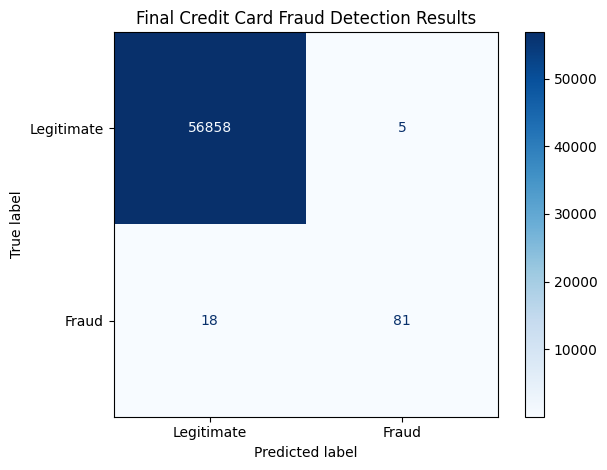

In [12]:

import matplotlib.pyplot as plt
from sklearn.metrics import ConfusionMatrixDisplay

ConfusionMatrixDisplay.from_predictions(
    y_test_new,
    final_predictions,
    display_labels=["Legitimate", "Fraud"],
    cmap="Blues",
    values_format="d"
)

plt.title("Final Credit Card Fraud Detection Results")
plt.tight_layout()
plt.savefig("final_confusion_matrix.png", dpi=300)
plt.show()
